<div style="background-color: #f5f8fb; border-left: 5px solid #277da8; padding: 16px 20px; margin-bottom: 18px; border-radius: 4px;">
<p style="color: #46586b; font-size: 12px; font-weight: 600; letter-spacing: 1px; margin: 0 0 7px 0;">SIMULACIÓN II</p>
<h1 style="color: #14283f; font-size: 29px; line-height: 1.3; margin: 0;">AJUSTE BAYESIANO DEL MODELO SIR CON PYMC</h1>
</div>

En este trabajo ajusto los parámetros del SIR con un **enfoque bayesiano usando PyMC**. Conservo los datos y las ecuaciones del brote de influenza; estimo las tasas de transmisión y remoción, junto con la dispersión de las observaciones. Obtengo muestras de la posterior mediante Metropolis y comparo el ajuste con los datos.

**Ejecución.** Uso Python 3.12 y PyMC 5.25.1. Las versiones de las bibliotecas están en [requirements-sir.txt](../requirements-sir.txt), junto con las instrucciones del [README](../README.md). Reinicio el kernel y ejecuto las celdas en orden; los datos y las gráficas están incluidos en este cuaderno.

## <span style="color: #277da8;">1. Bibliotecas y datos</span>

| Herramienta | Para qué la uso |
|---|---|
| NumPy y pandas [7–8] | Organizo los datos y calculo resúmenes de las muestras. |
| SciPy y Numba [11–12] | Integro el SIR y compilo el cálculo repetido de sus derivadas. |
| PyMC y PyTensor [5, 10] | Defino la posterior y ejecuto Metropolis con mi función numérica. |
| ArviZ [6] | Comparo las cadenas y dibujo las distribuciones posteriores. |
| Matplotlib e IPython [9, 13] | Presento tablas, gráficas y la solución final. |

Uso alias como `np`, `pd` y `pm` para llamar a estas bibliotecas. `np.array` guarda los registros y `pd.DataFrame` los muestra como tabla. Con `Path` organizo la salida; los módulos estándar también me permiten medir el tiempo, manejar advertencias y reutilizar integraciones.

Tomo $N=763$ estudiantes y los 15 registros de la tabla 1 de [1, pp. 1 y 3]. Interpreto $I(t)$ como los **infectados presentes** en cada día. Fijo $I(0)=1$ y adopto $R(0)=0$ del código [2]; así, $S(0)=762$. El día cero fija la condición inicial y ajusto los días 1 a 14.


In [1]:
import os  # Consulto los procesadores lógicos disponibles.
import time  # Mido el tiempo transcurrido con perf_counter.
import warnings  # Manejo las advertencias del integrador.
from pathlib import Path  # Construyo rutas sin concatenar separadores.
from functools import lru_cache  # Reutilizo resultados de una función.
from uuid import uuid4  # Identifico cada ejecución y su archivo de muestras.

print("Cargando bibliotecas…", flush=True)
import numpy as np  # Arreglos, operaciones numéricas y aleatoriedad.
import pandas as pd  # Tablas con filas y columnas identificadas.
import matplotlib.pyplot as plt  # Figuras, ejes y elementos gráficos.
from matplotlib.lines import Line2D  # Construyo la leyenda de los contornos.
import pymc as pm  # Modelo bayesiano y muestreo Metropolis.
import arviz as az  # Diagnósticos y visualización de la posterior.
import pytensor.tensor as pt  # Tipos simbólicos que utiliza PyMC.
from pytensor.compile.ops import as_op  # Puente hacia mi función numérica.
from numba import njit  # Compilación del cálculo de derivadas.
from scipy.integrate import odeint, ODEintWarning  # Solver y su advertencia.
from IPython.display import display, Markdown  # Salidas enriquecidas en Jupyter.
print(f"Bibliotecas listas. PyMC {pm.__version__}.", flush=True)

N = 763
# Genero los días 0 a 14; arange excluye el límite 15.
t = np.arange(15, dtype=float)
datos_school = np.array([1, 3, 6, 25, 73, 222, 294, 258,
                         237, 191, 125, 69, 27, 11, 4])
# Guardo el estado inicial en el orden S, I, R.
y0 = (762, 1, 0)
nombres = ["a", "b", "sigma"]

raiz = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
salida = raiz / "outputs" / "sir_pymc_sencillo" / "suave"
salida.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 10})
display(pd.DataFrame({"Día": t.astype(int), "Infectados": datos_school}))

Cargando bibliotecas…


Bibliotecas listas. PyMC 5.25.1.


,Día,Infectados
0,0,1
1,1,3
2,2,6
3,3,25
4,4,73
5,5,222
6,6,294
7,7,258
8,8,237
9,9,191


## <span style="color: #277da8;">2. Modelo con el que trabajo</span>

Divido la población en susceptibles $S$, infectados $I$ y retirados $R$. Conservo las ecuaciones (1)–(3) de [1, p. 2]:

$$
\frac{dS}{dt}=-aSI,\qquad
\frac{dI}{dt}=aSI-bI,\qquad
\frac{dR}{dt}=bI.
$$

| Cantidad | Lo que representa | Unidad |
|---|---|---|
| $a$ | Tasa que multiplica los contactos entre susceptibles e infectados. | persona⁻¹ día⁻¹ |
| $b$ | Tasa de salida del grupo de infectados. | día⁻¹ |
| $\sigma$ | Dispersión de las observaciones alrededor de la curva. | personas |

Los parámetros del sistema son $a$ y $b$. También estimo $\sigma$ para describir el error de observación. **Esta desviación es distinta del tamaño de paso de Metropolis.**

Supongo una población cerrada, mezcla homogénea y tasas constantes. Al sumar las ecuaciones obtengo $d(S+I+R)/dt=0$, por lo que mantengo $S+I+R=N$. Uso la forma $aSI$; si escribiera la transmisión como $\beta SI/N$, tendría $\beta=aN$.

Reutilizo `deriv` y `odeint` de [2]. Con `S, I, R = Y` separo las componentes del estado y con `return` devuelvo sus derivadas. `odeint` devuelve una fila por tiempo y tres columnas: $S$, $I$ y $R$.

En `resolver_sir` compruebo que el integrador termine, que los valores sean finitos y que la suma de las tres poblaciones siga siendo 763. Las tolerancias del código permiten pequeñas diferencias numéricas; una integración que incumpla estos controles no se usa para evaluar la propuesta.

Con `odeint(deriv, y0, tiempos, args=(N, a, b), ...)` paso las derivadas, el estado inicial, los tiempos y los parámetros. `full_output=True` devuelve también el estado del solver; `rtol` y `atol` controlan el error numérico, no la incertidumbre estadística. Convierto `ODEintWarning` en una excepción para rechazar integraciones fallidas.

El decorador `@njit` compila `deriv` en la primera llamada y reutiliza esa versión después. **Numba compila las derivadas y SciPy integra el sistema**; el paralelismo entre cadenas se controla por separado con `cores`.


In [2]:
# Reutilizo las derivadas de [2] y las compilo con Numba.
@njit
def deriv(Y, t, N, a, b):
    S, I, R = Y  # Desempaqueto las tres componentes del estado.
    return -a*S*I, a*S*I - b*I, b*I


def resolver_sir(a, b, tiempos=t):
    # Este filtro sólo afecta a las advertencias dentro del bloque.
    with warnings.catch_warnings():
        warnings.simplefilter("error", ODEintWarning)
        # full_output devuelve también el estado del integrador.
        sol, info = odeint(deriv, y0, tiempos, args=(N, a, b),
                           rtol=1e-8, atol=1e-8, full_output=True)
    if info["message"] != "Integration successful." or not np.isfinite(sol).all():
        raise RuntimeError("La integración no terminó correctamente.")
    if sol.min() < -1e-6 or not np.allclose(sol.sum(axis=1), N, rtol=0, atol=1e-5):
        raise RuntimeError("La solución incumple los controles de población.")
    return sol


# Esta primera integración también provoca la compilación inicial de deriv.
prueba = resolver_sir(0.002, 0.4)
assert np.allclose(prueba[0], y0)
assert np.allclose(prueba.sum(axis=1), N, rtol=0, atol=1e-5)

## <span style="color: #277da8;">3. Distribución que voy a muestrear</span>

### <span style="color: #a85d2a;">Cómo relaciono el modelo con los datos</span>

Llamo $\theta=(a,b,\sigma)$ a los parámetros y $y_j$ al número observado de infectados. Supongo errores normales, independientes una vez fijados los parámetros y con desviación común $\sigma$:

$$
y_j\mid\theta\sim\mathcal{N}\bigl(I(t_j;a,b),\sigma^2\bigr),
\qquad j=1,\ldots,14.
$$

Para cada propuesta de $a$ y $b$, integro el SIR y comparo su curva de infectados con los 14 datos del ajuste. El supuesto normal lleva a esta **log-verosimilitud**:

$$
\log L(\theta)=C-14\log\sigma
-\frac{1}{2\sigma^2}\sum_{j=1}^{14}\bigl[y_j-I(t_j;a,b)\bigr]^2.
$$

Omito $C=-14\log(2\pi)/2$ porque no depende de los parámetros. Conservo $-14\log\sigma$, porque también estimo $\sigma$: si dejara sólo el error cuadrático dividido entre $\sigma^2$, cambiaría la distribución que estoy muestreando. Adapto la expresión del ejemplo de [4].

### <span style="color: #a85d2a;">Priors y regla de Bayes</span>

Elijo priors uniformes independientes:

$$
a\sim U(0,0.01),\qquad b\sim U(0,1),\qquad\sigma\sim U(0,100).
$$

Uso estos límites para delimitar el ajuste. Son **restricciones de trabajo**, no mediciones de los autores: $a<0.01$ equivale a $\beta=aN<7.63$ día⁻¹; $b<1$ restringe la duración media $1/b$ a más de un día bajo el SIR, y $\sigma<100$ limita la dispersión a 100 personas. La positividad corresponde al significado de tasas y desviación.

Dentro de cada intervalo asigno densidad constante. Esto no convierte al prior en neutral bajo cualquier cambio de escala ni valida sus límites para el brote. **No he evaluado sensibilidad a otros priors**; los intervalos que obtenga quedan condicionados a esta elección.

Con la regla de Bayes actualizo los priors usando los datos:

$$
p(\theta\mid\mathbf{y})
=\frac{L(\theta)\,p(\theta)}{p(\mathbf{y})}
\;\propto\;L(\theta)\,p(\theta).
$$

La **posterior** describe la incertidumbre de los parámetros después de observar los datos, bajo estos supuestos. No necesito calcular $p(\mathbf{y})$ para Metropolis, porque se cancela al comparar propuestas.

### <span style="color: #a85d2a;">Cómo lo escribo en PyMC</span>

Con `with pm.Model() as modelo:` agrupo la definición del modelo. `pm.Uniform` define los priors y `pm.Potential` añade la log-verosimilitud a la log-densidad que PyMC evalúa. **Ambas partes definen la posterior**; `loglike` por sí sola sólo representa la verosimilitud.

Conservo Metropolis al pasar a PyMC. Puedo usarlo con la función numérica del SIR conectada mediante `as_op`, sin proporcionar gradientes. La curva depende de $a$ y $b$, mientras que $\sigma$ interviene al calcular la verosimilitud; esta separación permite reutilizar integraciones con una caché.

En `itypes=[pt.dscalar]*3` declaro tres entradas escalares de 64 bits; `otypes=[pt.dscalar]` pide una salida escalar. Devuelvo un arreglo NumPy de dimensión cero para cumplir esa interfaz. `as_op` conecta el cálculo con PyTensor, pero no aporta gradientes.

Con `@lru_cache(maxsize=256)` conservo curvas de pares $(a,b)$ repetidos; una propuesta que sólo cambie $\sigma$ puede reutilizarlas. Cada proceso tiene su caché. La vacío antes de muestrear y reinicio el cuaderno si cambio tiempos, población, condiciones iniciales o ecuaciones; si cambio los datos, repito el ajuste.


In [3]:
# Reutilizo una curva si se repiten a y b.
@lru_cache(maxsize=256)
def curva_infectados(a, b):
    # Excluyo el día cero y selecciono la columna de infectados.
    return resolver_sir(a, b)[1:, 1]


# Recibo tres escalares y devuelvo un escalar para PyTensor.
@as_op(itypes=[pt.dscalar]*3, otypes=[pt.dscalar])
def loglike(a, b, sigma):
    if not (0 < a < 0.01 and 0 < b < 1 and 0 < sigma < 100):
        return np.array(-np.inf)  # Rechazo esa propuesta.
    try:
        residuos = datos_school[1:] - curva_infectados(float(a), float(b))
    except (RuntimeError, ODEintWarning):
        return np.array(-np.inf)  # Rechazo esa propuesta.
    # NumPy calcula el logaritmo y suma los errores cuadrados por componente.
    valor = -len(residuos)*np.log(sigma) - np.sum((residuos/sigma)**2)/2
    return np.array(valor, dtype=float)


curva_infectados.cache_clear()
# El bloque with asocia priors y verosimilitud al mismo modelo.
with pm.Model() as modelo:
    # Trabajo en la escala original de cada parámetro.
    a = pm.Uniform("a", 0, 0.01, default_transform=None)
    b = pm.Uniform("b", 0, 1, default_transform=None)
    sigma = pm.Uniform("sigma", 0, 100, default_transform=None)
    # PyMC suma esta log-verosimilitud a los log-priors.
    pm.Potential("log_verosimilitud", loglike(a, b, sigma))

## <span style="color: #277da8;">4. Cómo obtengo las muestras</span>

Uso `pm.Metropolis` con propuestas normales simétricas. La aceptación compara la posterior propuesta con la actual:

$$
\alpha=\min\left\{1,
\frac{p(\theta^*\mid\mathbf{y})}{p(\theta\mid\mathbf{y})}\right\}.
$$

Si acepto, actualizo el estado; si rechazo, **conservo el valor anterior**. En PyMC 5.25.1 esta configuración actualiza las coordenadas por separado: en cada comparación cambia una componente de $\theta$. `blocked=True` agrupa las variables en un mismo paso, sin exigir aceptar o rechazar las tres juntas.

Con `S=np.diag(paso**2)` fijo la covarianza inicial de las propuestas. Durante `tune` se adapta su escala; después guardo `draws` estados por cadena, incluidos los repetidos. `sigma` sigue representando el error de observación, no el tamaño de la propuesta.

Escribo los puntos iniciales y la configuración en la celda siguiente. `cores` limita cuántas cadenas se ejecutan a la vez; no divide una cadena entre procesos. Comparar cadenas desde distintos inicios ayuda a revisar la exploración, pero su número no asegura convergencia.

`pm.sample` guarda las muestras en `idata.posterior`. Con `np.stack(..., axis=-1)` las ordeno como **cadena × muestra × parámetro** y con `reshape(-1, 3)` reúno los estados en tres columnas. Mantengo `idata` con sus cadenas separadas para los diagnósticos.

Antes de guardar, compruebo que la forma obtenida coincida con la solicitada y que todos los valores sean finitos. El tamaño impreso corresponde a las dimensiones reales. Guardo datos, configuración y un **identificador de ejecución** en `muestras.npz`, y muestro ese mismo identificador en el cuaderno. Escribo primero un archivo temporal y después lo sustituyo para evitar dejar un archivo final incompleto si se interrumpe la escritura.


Con `progressbar="split"` muestro una barra por cadena durante la ejecución. El contador incluye el calentamiento y los estados conservados: llega a 110 000 por cadena con esta configuración. El mensaje inicial aparece antes de preparar el muestreo; la primera llamada puede tardar mientras PyMC compila las funciones. La barra indica avance, no convergencia. En la vista HTML sólo se conserva el estado final.

In [4]:
draws = 100000
tune = 10000
semilla = 101
paso = np.array([0.00006, 0.025, 3.0])  # Escalas iniciales de las propuestas.

# Un punto inicial por cadena.
inicios = [dict(a=0.0015, b=0.30, sigma=10.0),
           dict(a=0.0030, b=0.65, sigma=25.0),
           dict(a=0.0018, b=0.60, sigma=40.0),
           dict(a=0.0025, b=0.40, sigma=18.0),
           dict(a=0.0020, b=0.50, sigma=30.0),
           dict(a=0.0022, b=0.55, sigma=22.0),
           dict(a=0.0017, b=0.45, sigma=15.0),
           dict(a=0.0028, b=0.35, sigma=12.0),
           dict(a=0.0019, b=0.70, sigma=28.0),
           dict(a=0.0026, b=0.25, sigma=20.0),
           dict(a=0.0024, b=0.75, sigma=35.0),
           dict(a=0.0016, b=0.80, sigma=32.0)]
cores = min(len(inicios), os.cpu_count() or 1)

# Muestreo con Metropolis; reviso la convergencia en la siguiente celda.
diagnostico_ok = False
curva_infectados.cache_clear()
inicio = time.perf_counter()
print(f"Iniciando {len(inicios)} cadenas: {tune:,} pasos de calentamiento y "
      f"{draws:,} estados por cadena. Preparando el muestreo…", flush=True)
with modelo:
    step = pm.Metropolis(S=np.diag(paso**2), blocked=True)
    idata = pm.sample(
        draws=draws, tune=tune, chains=len(inicios), cores=cores, blas_cores=cores,
        step=step, initvals=inicios, random_seed=semilla,
        discard_tuned_samples=True, progressbar="split", compute_convergence_checks=False
    )
tiempo_muestreo = time.perf_counter() - inicio

# Orden: cadena, muestra y parámetro (a, b, sigma).
posterior = np.stack([idata.posterior[p].values for p in nombres], axis=-1)
if posterior.shape != (len(inicios), draws, len(nombres)):
    raise RuntimeError("El muestreo está incompleto; no guardo sus resultados.")
if not np.isfinite(posterior).all():
    raise RuntimeError("La muestra contiene valores no finitos.")
muestras = posterior.reshape(-1, len(nombres))

# Guardo las muestras y la configuración de esta ejecución.
id_ejecucion = uuid4().hex
archivo_temporal = salida / f"muestras_{id_ejecucion}.tmp.npz"
np.savez_compressed(
    archivo_temporal, posterior=posterior, nombres=nombres,
    id_ejecucion=id_ejecucion, cadenas=posterior.shape[0], draws=posterior.shape[1],
    semilla=semilla, tune=tune, paso=paso,
    inicios=np.array([[p["a"], p["b"], p["sigma"]] for p in inicios]),
    N=N, y0=y0, t=t, infectados=datos_school,
    pymc_version=pm.__version__, tiempo_s=tiempo_muestreo
)
archivo_temporal.replace(salida / "muestras.npz")
print(f"Muestra: {posterior.shape[0]} cadenas × {posterior.shape[1]:,} estados.")
print(f"Calentamiento descartado: {tune:,} estados por cadena.")
print(f"Tiempo: {tiempo_muestreo:.1f} s. Ejecución: {id_ejecucion}")

Iniciando 12 cadenas: 10,000 pasos de calentamiento y 100,000 estados por cadena. Preparando el muestreo…


Multiprocess sampling (12 chains in 12 jobs)


Metropolis: [a, b, sigma]


 Progress                                   Draws    Sampling Speed    Elapsed   Remaining  
 ─────────────────────────────────────────────────────────────────────────────────────────── 
  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━   110000   1153.73 draws/s   0:01:35   0:00:00    
  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━   110000   1133.02 draws/s   0:01:37   0:00:00    
  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━   110000   1107.52 draws/s   0:01:39   0:00:00    
  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━   110000   1075.98 draws/s   0:01:42   0:00:00    
  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━   110000   1038.95 draws/s   0:01:45   0:00:00    
  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━   110000   1004.98 draws/s   0:01:49   0:00:00    
  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━   110000   977.60 draws/s    0:01:52   0:00:00    
  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━   110000   953.36 draws/s    0:01:55   0:00:00    
  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━   110000   923.57 draws/s    0:01:59   0:00:00    
  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━   110000   881.36 draws/s    0:02:04   0:00:00    
  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━   110000   840.18 draws/s    0:02:10   0:00:00    
  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━   110000   798.44 draws/s    0:02:17   0:00:00

Sampling 12 chains for 10_000 tune and 100_000 draw iterations (120_000 + 1_200_000 draws total) took 138 seconds.


Muestra: 12 cadenas × 100,000 estados.
Calentamiento descartado: 10,000 estados por cadena.
Tiempo: 138.7 s. Ejecución: 6585b4e7635243c7b3515df10e3a2b2e


## <span style="color: #277da8;">5. Reviso las cadenas</span>

Primero reviso las **cadenas por separado**. A la izquierda comparo sus densidades; a la derecha sigo los valores de cada parámetro en el orden del muestreo. La leyenda de ArviZ identifica las cadenas desde 0. Si una cadena permanece en otra región o muestra una tendencia persistente, reunir todas las muestras podría ocultar el problema.

Con `az.summary` calculo los diagnósticos usando **todas las muestras conservadas**:

| Diagnóstico | Cómo lo interpreto |
|---|---|
| $\widehat{R}$ | Compara el comportamiento entre cadenas y dentro de ellas. Valores próximos a 1 son favorables. |
| ESS | Resume cuánta información aporta la muestra correlacionada para estimar una cantidad. Distingo la parte central (`bulk`) y las colas (`tail`). |
| MCSE | Estima el error de Monte Carlo de los resúmenes. No representa la dispersión de los datos ni sustituye al intervalo creíble. |

Requiero diagnósticos finitos, $\widehat{R}\leq1.01$, ESS central y de colas de al menos 400, y un MCSE de la media menor o igual al 2 % de la desviación posterior (`MCSE/DE`). Si alguno falla, detengo la ejecución antes de presentar la solución. Este último control limita el error numérico de la media; no garantiza la misma precisión para todos los cuantiles. Son criterios de diagnóstico; **no son una demostración de convergencia ni de adecuación del SIR**.

Para esta revisión uso `idata`, el objeto `InferenceData` que devuelve PyMC, porque conserva las dimensiones de cadena y muestra. `az.plot_trace` produce las figuras y `az.summary(..., kind="diagnostics")` la tabla. Con `np.isfinite(...).all()` compruebo que todos los diagnósticos sean finitos. Comparo el mayor R-hat y MCSE/DE, y el menor ESS, con los límites indicados: así reviso los tres parámetros. `.style.format` sólo redondea la presentación de la tabla.


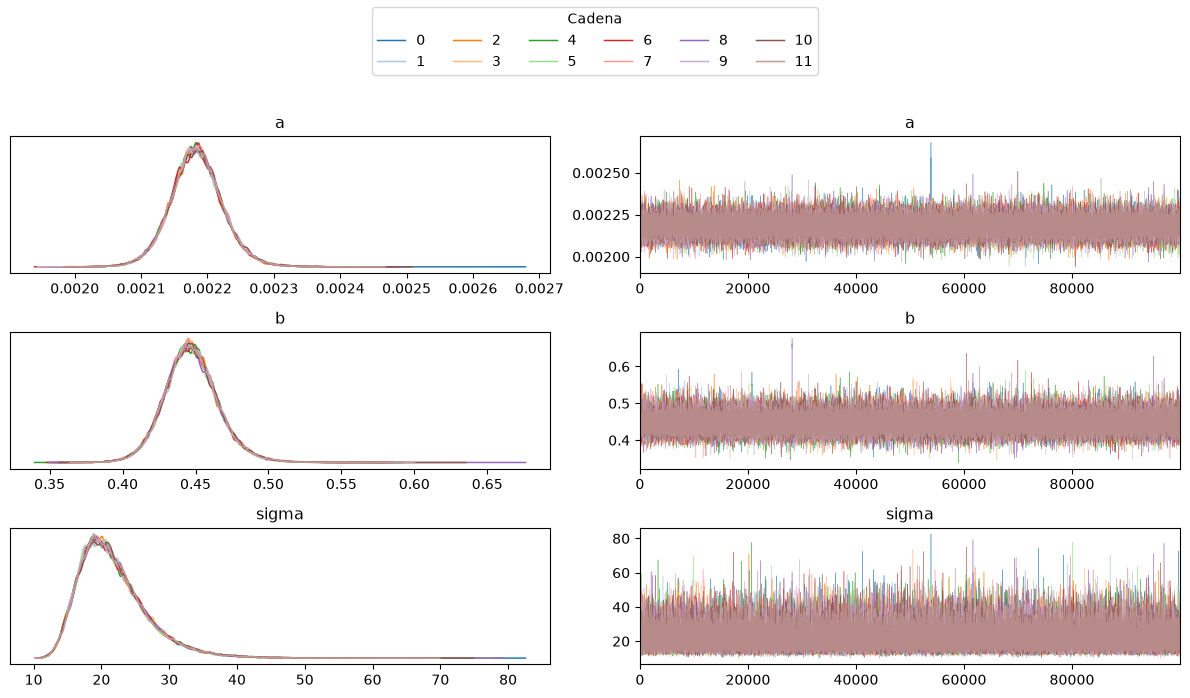

,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat,MCSE/DE
a,9.242e-08,8.271e-08,1.885e+05,2.219e+05,1,0.002314
b,4.379e-05,4.1e-05,1.902e+05,2.246e+05,1,0.002311
sigma,0.01407,0.01799,1.581e+05,1.79e+05,1,0.002688


In [5]:
# ArviZ dibuja las densidades, las trazas y la leyenda de las cadenas.
ejes = az.plot_trace(
    idata, var_names=nombres, compact=False, legend=True, show=False,
    figsize=(12, 7), chain_prop={"color": plt.get_cmap("tab20").colors},
    trace_kwargs={"alpha": 0.65, "linewidth": 0.4}
)
leyenda = ejes[0, 1].get_legend()
plt.figlegend(handles=leyenda.legend_handles, loc="upper center", ncol=6, title="Cadena")
leyenda.remove()
plt.tight_layout(rect=(0, 0, 1, 0.86))
plt.savefig(salida / "trazas.png", dpi=180)
plt.show()

# Calculo los diagnósticos y el error relativo de Monte Carlo.
diagnostico = az.summary(idata, var_names=nombres, kind="diagnostics", round_to="none")
diagnostico["MCSE/DE"] = diagnostico["mcse_mean"] / muestras.std(axis=0, ddof=1)
display(diagnostico.style.format("{:.4g}"))

# Todos los parámetros deben cumplir los mismos criterios.
diagnostico_ok = (
    np.isfinite(diagnostico.to_numpy()).all()
    and diagnostico["r_hat"].max() <= 1.01
    and diagnostico["ess_bulk"].min() >= 400
    and diagnostico["ess_tail"].min() >= 400
    and diagnostico["MCSE/DE"].max() <= 0.02
)
if not diagnostico_ok:
    raise RuntimeError("Reviso las trazas y el muestreo antes de interpretar el ajuste.")

En las trazas guardadas, las cadenas recorren regiones similares y sus densidades se superponen. Esto coincide con los diagnósticos de la tabla y permite resumir esta ejecución. Mantengo los valores altos de $\sigma$: su distribución tiene una cola derecha y eliminarlos cambiaría la muestra posterior.

## <span style="color: #277da8;">6. Distribución conjunta de los parámetros</span>

Con `az.plot_pair` dibujo la gráfica triangular. En la diagonal veo cada distribución marginal; debajo, las relaciones por pares. Los contornos encierran aproximadamente **50 %, 80 % y 95 % de probabilidad posterior**, según la densidad estimada. La leyenda identifica cada límite; cada región incluye también su interior.

Estas regiones dependen de los datos, el modelo y los priors. Son regiones bidimensionales por pares, no una región conjunta de los tres parámetros. En las marginales, la altura representa densidad y la probabilidad corresponde al área de un intervalo.

Uso todas las muestras conservadas y suavizo las marginales con el ancho de banda de Scott. La KDE modifica el dibujo; los cuantiles y diagnósticos se calculan con las muestras. **Una curva suave no demuestra buena exploración de la posterior.**

`kind="kde"` selecciona la estimación de densidad y `marginals=True` añade las marginales. Con `MapLabeller` cambio los rótulos sin renombrar las variables. La matriz `ejes` permite ajustar y guardar la figura con Matplotlib.


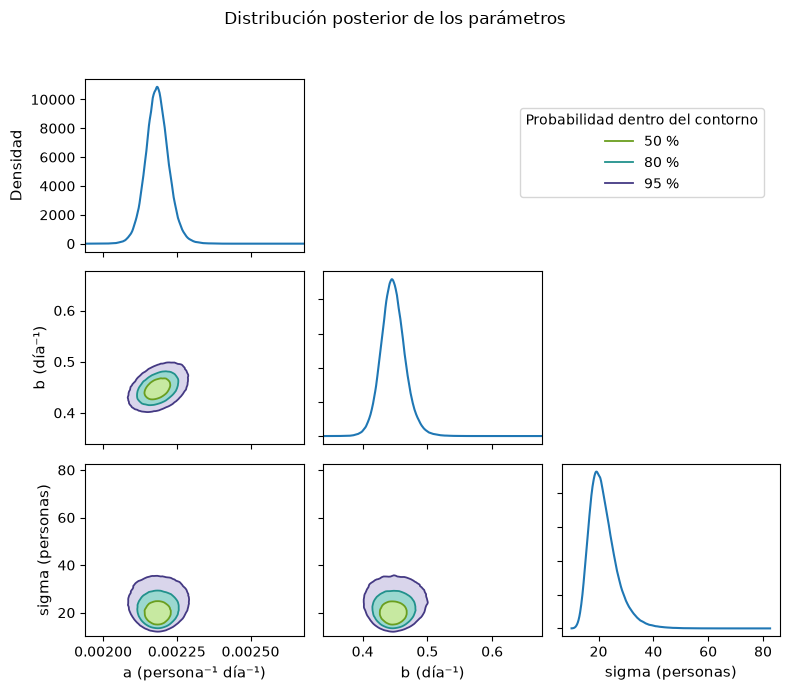

In [6]:
# Uso la muestra posterior completa para estimar la densidad.
seleccion = idata.posterior[nombres]
# Sólo cambio las etiquetas visibles: las variables siguen siendo a, b y sigma.
rotulos = az.labels.MapLabeller(var_name_map={
    "a": "a (persona⁻¹ día⁻¹)", "b": "b (día⁻¹)", "sigma": "sigma (personas)"})
ejes = az.plot_pair(seleccion, var_names=nombres, kind="kde", marginals=True,
    marginal_kwargs={"bw": "scott"},
    labeller=rotulos, figsize=(8, 7), textsize=10, show=False,
    kde_kwargs={"hdi_probs": [0.50, 0.80, 0.95],
                # ArviZ ordena los niveles de menor a mayor densidad:
                # contornos del 95 %, 80 %, 50 % y el máximo.
                "contour_kwargs": {"linewidths": 1.3,
                                   "colors": ["#443983", "#21918c", "#6a9e1f", "#6a9e1f"]},
                "contourf_kwargs": {"colors": ["white", "#d9d5eb", "#9bd8d0", "#c7e9a1"]}})
ejes[0, 0].set_ylabel("Densidad")
fig = ejes[0, 0].figure
fig.suptitle("Distribución posterior de los parámetros")
fig.legend(
    handles=[Line2D([0], [0], color=color, lw=1.3, label=etiqueta)
             for color, etiqueta in [("#6a9e1f", "50 %"),
                                      ("#21918c", "80 %"), ("#443983", "95 %")]],
    title="Probabilidad dentro del contorno",
    loc="upper right", bbox_to_anchor=(0.97, 0.85), fontsize=10, title_fontsize=10
)
ejes[-1, 0].locator_params(axis="x", nbins=3)
fig.tight_layout(rect=(0, 0, 1, 0.95))
# Guardo una imagen PNG y un PDF; show muestra la figura en el cuaderno.
fig.savefig(salida / "posterior_triangular.png", dpi=240, bbox_inches="tight")
fig.savefig(salida / "posterior_triangular.pdf", bbox_inches="tight")
plt.show()

En el panel de $a$ frente a $b$ veo una región inclinada hacia arriba: una mayor transmisión puede compensarse parcialmente con una mayor remoción para describir estos datos. Por eso conviene interpretar ambas tasas juntas. Los priors son independientes, pero esa independencia no se conserva necesariamente después de observar el brote.

La posterior de $\sigma$ se extiende más hacia la derecha. Un intervalo simétrico alrededor de la mediana no describiría bien esa forma; en la siguiente tabla uso directamente sus percentiles.

## <span style="color: #277da8;">7. Resumo los parámetros y comparo el ajuste</span>

Resumo cada parámetro con la **mediana posterior** y los percentiles 2.5 y 97.5. Estos delimitan un **intervalo creíble del 95 %**, con aproximadamente un 2.5 % de probabilidad posterior en cada cola. Uso el término *creíble* porque estoy describiendo la incertidumbre posterior del parámetro, condicionada a los datos, al modelo y a los priors.

La tabla contiene un intervalo para cada parámetro por separado. No es una región conjunta del 95 % para los tres, ni un intervalo para el número de infectados. Los contornos de la figura anterior se construyen con regiones de mayor densidad, mientras que aquí uso percentiles de colas iguales.

Con `np.quantile(..., axis=0)` calculo los percentiles de cada columna. Redondeo sólo la presentación y conservo la precisión interna para los cálculos.

Dibujo una curva SIR usando las medianas de $a$ y $b$. La tomo como una curva representativa, no como el mínimo exacto del error ni como la mediana de todas las curvas. Con 500 estados posteriores obtengo una **banda puntual de trayectoria del 95 %**, que incluye incertidumbre de los parámetros y no el error de observación.

`np.linspace(0, 14, 281)` crea la malla. Fijo la semilla 505 y selecciono posiciones con `choice(..., replace=False)`: no repito posiciones, pero conservo los parámetros repetidos que pueda haber producido Metropolis. Con `scatter`, `plot` y `fill_between` dibujo datos, curva y banda. `.style.format` sólo cambia los decimales visibles en la tabla.


,Unidad,Mediana,2.5 %,97.5 %
Parámetro,,,,
a,persona⁻¹ día⁻¹,0.00218275,0.00210635,0.0022651
b,día⁻¹,0.446388,0.411551,0.486973
sigma,personas,20.8842,14.3444,34.475


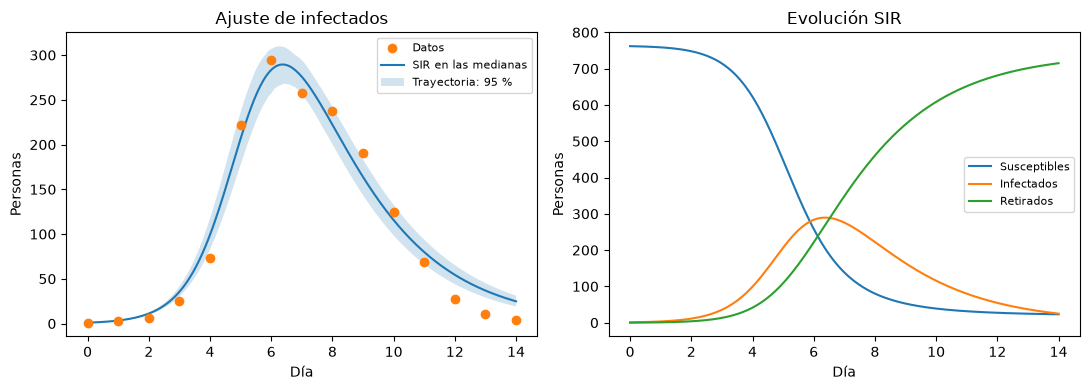

In [7]:
# axis=0 calcula los cuantiles por parámetro.
q025, mediana, q975 = np.quantile(muestras, [0.025, 0.5, 0.975], axis=0)
resumen = pd.DataFrame({"Mediana": mediana, "2.5 %": q025, "97.5 %": q975},
                       index=pd.Index(nombres, name="Parámetro"))
resumen.insert(0, "Unidad", ["persona⁻¹ día⁻¹", "día⁻¹", "personas"])
display(resumen.style.format("{:.6g}", subset=["Mediana", "2.5 %", "97.5 %"]))

a_est, b_est, sigma_est = mediana
t_fino = np.linspace(0, 14, 281)
solucion = resolver_sir(a_est, b_est, t_fino)
# La semilla fija la selección de trayectorias usada en esta figura.
rng = np.random.default_rng(505)
indices = rng.choice(len(muestras), min(500, len(muestras)), replace=False)
# Integro el SIR con los parámetros de cada estado seleccionado.
curvas = np.array([resolver_sir(p[0], p[1], t_fino)[:, 1] for p in muestras[indices]])
lim_inf, lim_sup = np.quantile(curvas, [0.025, 0.975], axis=0)

# fig es la figura completa; axes contiene los dos paneles.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(t, datos_school, color="tab:orange", label="Datos", zorder=3)
axes[0].plot(t_fino, solucion[:, 1], label="SIR en las medianas")
axes[0].fill_between(t_fino, lim_inf, lim_sup, alpha=0.2, label="Trayectoria: 95 %")
axes[0].set_title("Ajuste de infectados")
for j, etiqueta in enumerate(["Susceptibles", "Infectados", "Retirados"]):
    axes[1].plot(t_fino, solucion[:, j], label=etiqueta)
axes[1].set_title("Evolución SIR")
for ax in axes:
    ax.set(xlabel="Día", ylabel="Personas")
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(salida / "ajuste.png", dpi=180)
plt.show()

El máximo observado es de **294 infectados en el día 6**. La curva en las medianas pasa cerca del pico y sigue el descenso del brote, pero queda por encima de los registros finales. Esa diferencia es la que reviso con los residuos en la siguiente sección.

En el segundo panel sigo las tres poblaciones inferidas por el SIR; sólo observé infectados: los susceptibles disminuyen y los retirados aumentan, mientras los infectados primero crecen y después bajan. La banda del primer panel muestra cuánto cambian las trayectorias al variar los parámetros posteriores. Todavía no incluye el ruido de observación, así que no la uso para decidir si cada dato observado es compatible con la predictiva.

## <span style="color: #277da8;">8. Reviso los residuos y simulo observaciones</span>

Calculo los residuos como **observado menos modelo**:

$$
r_j=y_j-I(t_j;\widehat{a},\widehat{b}),\qquad
\operatorname{RMSE}=\sqrt{\frac{1}{14}\sum_{j=1}^{14}r_j^2}.
$$

En esta expresión, $\widehat{a}$ y $\widehat{b}$ son las medianas posteriores. Un residuo positivo indica que la curva queda por debajo del dato; uno negativo indica que lo sobreestima. El RMSE resume el tamaño de esos errores en personas, usando los mismos días con los que ajusté el modelo.

Después tomo 2000 estados posteriores. Para cada uno integro la curva y añado errores normales independientes con su valor de $\sigma$:

$$
I_j^{\mathrm{rep}}=I(t_j;a,b)+\sigma Z_j,
\qquad Z_j\sim\mathcal{N}(0,1).
$$

Así incluyo tanto la incertidumbre de los parámetros como el error de observación. La **banda predictiva puntual** corresponde a réplicas de estos mismos días. Con `parametros[:, 2, None]` convierto los valores de $\sigma$ en una columna, uno por réplica, para multiplicarlos por sus errores diarios.

Conservo los valores negativos de las réplicas para examinar una limitación de usar una normal con datos de conteo. No los recorto ni modifico las observaciones originales.

`rng.normal(size=medias.shape)` genera una matriz de errores normales estándar con una fila por réplica y una columna por día. NumPy extiende la columna `parametros[:, 2, None]` a esos días al multiplicar: esta regla se llama *broadcasting*. Después `np.quantile(..., axis=0)` resume cada día entre las réplicas. En `np.any(replicas < 0, axis=1)` reviso si cada serie tiene algún negativo; la media de esos valores booleanos da la fracción de series afectadas.


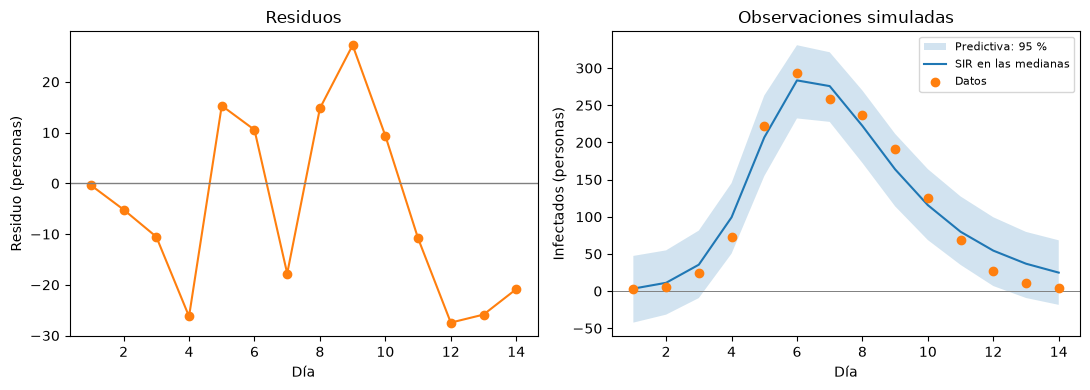

RMSE: 17.9 personas
Series simuladas con algún valor negativo: 69.2 %


In [8]:
I_ajustado = resolver_sir(a_est, b_est)[:, 1]
# Un residuo negativo indica sobreestimación de la curva.
residuos = datos_school[1:] - I_ajustado[1:]
rmse = np.sqrt(np.mean(residuos**2))

rng = np.random.default_rng(606)
indices = rng.choice(len(muestras), min(2000, len(muestras)), replace=False)
parametros = muestras[indices]
medias = np.array([resolver_sir(p[0], p[1])[1:, 1] for p in parametros])
# A cada curva le sumo errores normales con su propio sigma.
replicas = medias + parametros[:, 2, None]*rng.normal(size=medias.shape)
pred_inf, pred_sup = np.quantile(replicas, [0.025, 0.975], axis=0)
# any revisa cada fila; mean convierte los True/False en una proporción.
fraccion_negativa = np.mean(np.any(replicas < 0, axis=1))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(t[1:], residuos, "o-", color="tab:orange")
axes[0].axhline(0, color="gray", lw=1)
axes[0].set(xlabel="Día", ylabel="Residuo (personas)", title="Residuos")
axes[1].fill_between(t[1:], pred_inf, pred_sup, alpha=0.2, label="Predictiva: 95 %")
axes[1].plot(t[1:], I_ajustado[1:], label="SIR en las medianas")
axes[1].scatter(t[1:], datos_school[1:], color="tab:orange", label="Datos", zorder=3)
axes[1].axhline(0, color="gray", lw=0.7)
axes[1].set(xlabel="Día", ylabel="Infectados (personas)", title="Observaciones simuladas")
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(salida / "residuos_predictiva.png", dpi=180)
plt.show()
print(f"RMSE: {rmse:.1f} personas")
print(f"Series simuladas con algún valor negativo: {100*fraccion_negativa:.1f} %")

En los días **11 a 14** los residuos son negativos: el SIR sobreestima de forma consecutiva los infectados al final del brote. El RMSE resume el error global, pero ese patrón me permite localizar dónde falla la curva.

Al añadir el error normal, la banda predictiva se amplía y aparecen réplicas con conteos negativos. La fracción impresa cuenta series con **al menos un valor negativo**, no el porcentaje de observaciones negativas. Es una limitación del modelo de observación para conteos pequeños, que sigue presente aunque las cadenas superen sus diagnósticos.

## <span style="color: #277da8;">9. Resultado y conclusión</span>

Presento las medianas como solución puntual y las acompaño con los intervalos de la sección 7. Con `np.argmax(solucion[:, 1])` localizo el pico en la malla. El bloque siguiente inserta los valores calculados con cadenas `f"..."`, para mantener la conclusión consistente con la ejecución.


In [9]:
if not diagnostico_ok:
    raise RuntimeError("Primero debo superar los controles de las cadenas.")

pico = np.argmax(solucion[:, 1])
display(Markdown(
    "### <span style='color: #277da8;'>Solución final</span>\n\n"
    f"Estimo **a = {a_est:.6f} persona⁻¹ día⁻¹**, **b = {b_est:.3f} día⁻¹** "
    f"y **sigma = {sigma_est:.1f} personas**, usando las medianas posteriores. "
    "Los intervalos creíbles del 95 % están en la tabla de la sección 7.\n\n"
    f"La curva en las medianas alcanza aproximadamente **{solucion[pico, 1]:.0f} "
    f"infectados** en el día **{t_fino[pico]:.2f}**, con una malla de 0.05 días. "
    f"El RMSE de los días del ajuste es **{rmse:.1f} personas**."
))

### <span style='color: #277da8;'>Solución final</span>

Estimo **a = 0.002183 persona⁻¹ día⁻¹**, **b = 0.446 día⁻¹** y **sigma = 20.9 personas**, usando las medianas posteriores. Los intervalos creíbles del 95 % están en la tabla de la sección 7.

La curva en las medianas alcanza aproximadamente **289 infectados** en el día **6.35**, con una malla de 0.05 días. El RMSE de los días del ajuste es **17.9 personas**.

**El ajuste reproduce el pico y la evolución general del brote, con una sobreestimación al final.** Las medianas y sus intervalos creíbles resumen la incertidumbre de $a$, $b$ y $\sigma$ dentro del modelo elegido. La inclinación entre $a$ y $b$ en la gráfica triangular muestra por qué no basta con interpretar cada tasa de forma aislada.

La revisión de las cadenas respalda el resumen numérico de esta posterior. La revisión de residuos y réplicas responde a otra pregunta: qué aspectos de los datos consigue describir el modelo. Aumentar las muestras reduce la incertidumbre de Monte Carlo, pero no elimina el desajuste de los últimos días ni los conteos negativos de la predictiva normal.

Para delimitar el resultado, mantengo tres condiciones:

- **Estado inicial:** fijo la población y las condiciones iniciales; sus posibles errores no están incluidos en los intervalos.
- **Priors:** conservo los límites especificados y no he evaluado sensibilidad a otras elecciones.
- **Predicción:** todos los días analizados pertenecen al ajuste; no he reservado observaciones para evaluar predicciones nuevas.

## <span style="color: #277da8;">10. Código que reutilizo y referencias</span>

Identifico de dónde tomo el modelo y qué adapto:

| Parte | Origen | Lo que hago en este cuaderno |
|---|---|---|
| Datos, ecuaciones, `deriv` y `odeint` | [1–2] | Conservo el SIR y reviso la integración y la población. |
| Log-verosimilitud | Ejemplo de [4] | Sustituyo la recta por la curva SIR y estimo $\sigma$. |
| Idea de Metropolis | [3–4] | Uso la implementación `pm.Metropolis` de PyMC. |
| Posterior y muestreo | PyMC [5] | Combino `pm.Uniform`, `pm.Potential` y `pm.sample`. |
| Diagnósticos y gráfica triangular | ArviZ [6] | Comparo cadenas y represento las distribuciones posteriores. |

El artículo [1] ajusta los parámetros del SIR mediante un algoritmo genético. El objetivo de este ejercicio es resolver el ajuste con un enfoque bayesiano usando **PyMC**. Para ello, conservo los datos y las ecuaciones del artículo y planteo la verosimilitud y los priors descritos en este cuaderno.

1. Medel Esquivel et al. (2021). *The inverse problem of a dynamical system solved with genetic algorithms*. J. Phys.: Conf. Ser. 1723, 012021. [DOI](https://doi.org/10.1088/1742-6596/1723/1/012021). Población en p. 1, ecuaciones (1)–(3) en p. 2 y tabla 1 en p. 3; numeración impresa.
2. Medetl. *InverseProblem*, [SIR_AG.ipynb](https://github.com/Medetl/InverseProblem/blob/6db98f279be8527c112220d6b57c3902b2190ae1/SIR_AG.ipynb), versión `6db98f2`.
3. Medel Esquivel et al. (2021). *An introduction to Markov Chain Monte Carlo*. BEIO 37(1), 47–74. Tabla 7 en p. 64 y discusión de aceptación y diagnóstico en p. 65.
4. Gómez-Vargas. *IntroMCMC*, [EjemploMCMC.ipynb](https://github.com/igomezv/IntroMCMC/blob/29807f91780599392e62c7a2b40c08ec6317e9d3/EjemploMCMC.ipynb), versión `29807f9`.
5. PyMC. [Funciones externas con PyTensor](https://www.pymc.io/projects/examples/en/latest/howto/blackbox_external_likelihood_numpy.html), [`Potential`](https://www.pymc.io/projects/docs/en/stable/api/model/generated/pymc.model.core.Potential.html) y [`sample`](https://www.pymc.io/projects/docs/en/stable/api/generated/pymc.sample.html). Uso PyMC 5.25.1; estos enlaces `stable` pueden describir versiones posteriores. La versión ejecutada se muestra al importar y se guarda con las muestras.
6. ArviZ. Documentación oficial: [diagnósticos con `summary`](https://python.arviz.org/en/v0.22.0/api/generated/arviz.summary.html) y [gráficas de pares y marginales con `plot_pair`](https://python.arviz.org/en/v0.22.0/api/generated/arviz.plot_pair.html).
7. NumPy. [Guía de arreglos y operaciones básicas](https://numpy.org/doc/stable/user/absolute_beginners.html). Documentación oficial.
8. pandas. [Introducción a las tablas y operaciones con `DataFrame`](https://pandas.pydata.org/docs/user_guide/10min.html). Documentación oficial.
9. Matplotlib. [Tutorial de `pyplot`](https://matplotlib.org/stable/tutorials/pyplot.html). Documentación oficial para construir figuras, ejes y gráficas.
10. PyTensor. [Creación de operaciones en Python](https://pytensor.readthedocs.io/en/stable/extending/creating_an_op.html). Documentación oficial sobre la conexión de funciones numéricas con el cálculo simbólico.
11. Numba. [Compilación de funciones con `jit` y `njit`](https://numba.readthedocs.io/en/stable/user/jit.html). Documentación oficial.
12. SciPy. Documentación oficial de [`odeint`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.odeint.html) y [`ODEintWarning`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.ODEintWarning.html).
13. IPython. [Módulo `IPython.display`](https://ipython.readthedocs.io/en/stable/api/generated/IPython.display.html), incluidas las herramientas `display` y `Markdown`. Documentación oficial.
14. Python. [`functools.lru_cache`](https://docs.python.org/3/library/functools.html#functools.lru_cache). Documentación oficial de la caché utilizada.

**Uso de IA.** Utilicé IA como apoyo en la adaptación y revisión del código y las explicaciones.

**Cómo repetir el ajuste.** Reinicio el kernel y ejecuto las celdas en orden. La celda de muestreo genera las cadenas indicadas en `inicios`. Comparo el identificador impreso con `id_ejecucion` en `muestras.npz` si reutilizo el archivo; las salidas guardadas se pueden consultar sin repetir el cálculo.